# Complex Count Sketch — 可查阅笔记本

对应论文 *Complex Count Sketch: Mergeable Frequency-Moment and p-Star Join
Size Estimation* 的核心实验。数据在 `ccs-release/data/`,核心库在
`ccs-release/ccs.py`。全部 cell 可直接运行(快速档参数;论文级参数见
`ccs-release/experiments/`)。

In [1]:
import os, sys, itertools, math
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('ccs-release'))
import ccs, loaders
print('numpy', np.__version__)

numpy 1.26.4


## 1. 草图机制

CCS 把元素 α 以 p 次单位根 g(α) 哈希进复数计数器
C[j,s] = Σ_α f_α·g(α)。两条代数性质:g^p = 1(对角自乘变成 f^p)、
根和为零(交叉项期望消失)。p=2 时即 Count Sketch 的 ±1。

In [2]:
# 一个 3-star 的最小演示:三列共享 h,g,逐元素相乘后取实部中位数
rng = np.random.default_rng(0)
U, W = 2000, 64
F = [np.bincount(rng.integers(0, U, size=50000), minlength=U).astype(float)
     for _ in range(3)]
truth = float((F[0] * F[1] * F[2]).sum())
re, im = ccs.star_rows(F, 3, W, np.random.default_rng(1), d=32)
print(f'3-star truth={truth:.6g}  estimate={ccs.median(re):.6g}')

3-star truth=3.13606e+07  estimate=4.14687e+07


## 2. 精确方差核验(式 13 的共址模式精确枚举)

错位实例 f1=(H,0,0,1), f2=(0,H,0,1), f3=(0,0,H,1)(J=1, D=4):
Var[Re R_j] = 3H²/(2w) + (H⁶+3H⁴)/(2w²),无蒙特卡洛、逐模式精确。

In [3]:
def partitions(el):
    if not el:
        yield []
    else:
        f, rest = el[0], el[1:]
        for p in partitions(rest):
            for i in range(len(p)):
                yield p[:i] + [[f] + p[i]] + p[i + 1:]
            yield [[f]] + p

def var_given_placement(FC, assign):
    n = len(FC[0]); E_R = E_R2 = 0.0
    for g in itertools.product(range(3), repeat=n):
        gr = [np.exp(2j * np.pi * k / 3) for k in g]
        R = 0j
        for s in set(assign):
            Z = 1 + 0j
            for i, f in enumerate(FC):
                y = 0j
                for it in range(n):
                    if assign[it] == s:
                        y += f[it] * gr[it]
                Z = Z * y
            R = R + Z
        E_R += R / 3 ** n
        E_R2 += R.real ** 2 / 3 ** n
    return E_R2 - abs(E_R) ** 2

for H in (7.0, 50.0):
    FC = [np.array([H,0,0,1.0]), np.array([0,H,0,1.0]), np.array([0,0,H,1.0])]
    for w in (100, 1000):
        total = 0.0
        for part in partitions([0,1,2,3]):
            k = len(part); assign = {}
            for bi, blk in enumerate(part):
                for e in blk: assign[e] = bi
            prob = math.prod(range(w-k+1, w+1)) / w**4
            total += prob * var_given_placement(FC, [assign[e] for e in range(4)])
        pred = 3*H*H/(2*w) + (H**6+3*H**4)/(2*w**2)
        print(f'H={H:g} w={w}: exact={total:.10g}  公式={pred:.10g}')

H=7 w=100: exact=6.9776  公式=6.9776
H=7 w=1000: exact=0.135926  公式=0.135926
H=50 w=100: exact=782225  公式=782225
H=50 w=1000: exact=7825.625  公式=7825.625


## 3. 奇数阶实数乘子:存在、无偏、但更贵

定理 4.2:偶数阶 p≥4 无实数乘子;奇数阶只需消去低阶奇矩。
精确线性求解 + 精确期望(动态规划,非采样)验证无偏性。

In [4]:
for p in (3, 5, 7):
    if p == 3:
        s, w = np.array([-1.0, 1.0, 2.0]), np.array([7/12, 1/4, 1/6])
    else:
        sup = {5: np.array([-1.0, 0.5, 1.5, 2.5]),
               7: np.array([-2.0, -1.5, -1.0, 1.5, 4.0])}[p]
        s = sup
        w = ccs.exact_solve_real_multiplier(p, sup)
    mu = ccs.g_moments(s, w, p)
    rng0 = np.random.default_rng(11)
    freq = np.bincount(rng0.integers(0, 200, size=50_000), minlength=200).astype(float)
    E = ccs.exact_power_expectation(p, freq, mu)
    truth = float((freq**p).sum())
    worst = max(abs(float((w*s**m).sum())) for m in range(1, p, 2))
    print(f'p={p}: 最差|奇矩|={worst:.1e}, 精确期望/F_p - 1 = {E/truth-1:.1e}')

p=3: 最差|奇矩|=5.6e-17, 精确期望/F_p - 1 = -1.4e-14
p=5: 最差|奇矩|=1.0e-16, 精确期望/F_p - 1 = 9.0e-13
p=7: 最差|奇矩|=6.7e-16, 精确期望/F_p - 1 = -4.1e-11


## 4. F_p 估计与宽度扫描(图 2)

zipf1.1:误差每个 w 翻倍下降约 2×,快于 w^{-1/2} 噪声率(中位数误差此时
由碰撞偏移主导)。

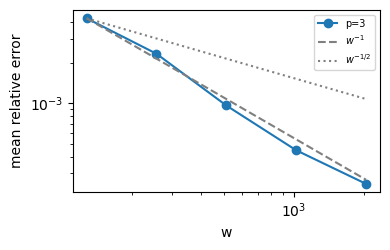

['4.3e-03', '2.3e-03', '9.6e-04', '4.5e-04', '2.5e-04']


In [5]:
k, c = loaders.lp_column('zipf1.1.dat')
f = np.zeros(len(k)); f[np.searchsorted(k, k)] = c
truth = float((f**3).sum())
ws = [128, 256, 512, 1024, 2048]
errs = [np.mean([abs(ccs.median(ccs.f_p_rows(f, 3, w, np.random.default_rng(500+t), d=64)[0]) - truth)/truth
                 for t in range(10)]) for w in ws]
plt.figure(figsize=(4, 2.6))
plt.loglog(ws, errs, 'o-', label='p=3')
plt.loglog(ws, [errs[0]*(w/ws[0])**-1 for w in ws], '--', color='gray', label='$w^{-1}$')
plt.loglog(ws, [errs[0]*(w/ws[0])**-0.5 for w in ws], ':', color='gray', label='$w^{-1/2}$')
plt.xlabel('w'); plt.ylabel('mean relative error'); plt.legend(fontsize=7)
plt.tight_layout(); plt.show()
print([f'{e:.1e}' for e in errs])

## 5. T-MCCS 与聚合器(表 3 协议,快速档)

中位数族是对的(碰撞使行分布右偏);T-MCCS 用虚部信号再买一个因子。

In [6]:
def make_freq(alpha, D=1000, N=100_000, seed=12345):
    rng = np.random.default_rng(seed)
    if alpha == 0.0:
        items = rng.integers(0, D, size=N)
    else:
        w = np.arange(1, D+1, dtype=float) ** (-alpha)
        items = rng.choice(D, size=N, p=w/w.sum())
    return np.bincount(items, minlength=D).astype(float)

for alpha in (0.0, 1.1, 2.0):
    freq = make_freq(alpha)
    truth = float((freq**3).sum())
    A, G, Mn = [], [], []
    for t in range(200):
        rng = np.random.default_rng(1000+t)
        re, im = ccs.f_p_rows(freq, 3, 256, rng, d=64)
        A.append(abs(ccs.median(re)-truth)/truth)
        G.append(abs(ccs.tmccs(re, im)-truth)/truth)
        Mn.append(abs(ccs.mean(re)-truth)/truth)
    print(f'alpha={alpha}: median={np.mean(A):.3e}  T-MCCS={np.mean(G):.3e} '
          f'(T/med={np.mean(G)/np.mean(A):.2f})  mean={np.mean(Mn):.3e} '
          f'(mean/med={np.mean(Mn)/np.mean(A):.1f})')

alpha=0.0: median=3.928e-02  T-MCCS=3.901e-02 (T/med=0.99)  mean=3.033e-02 (mean/med=0.8)


alpha=1.1: median=2.248e-03  T-MCCS=1.495e-03 (T/med=0.66)  mean=9.055e-03 (mean/med=4.0)


alpha=2.0: median=2.412e-05  T-MCCS=1.070e-05 (T/med=0.44)  mean=3.192e-03 (mean/med=132.4)


## 6. p-star:CCS vs 实数基线(zipf1.1×3)

per-edge 实数构造在等字节下通常更准;共享复根保留一根哈希、精确碰撞律、
虚部信号、F_p 兼用;shared-sign(±1 同根)因 E[g³]=0 有偏。

In [7]:
fc = [loaders.lp_column('zipf1.1.dat'+s) for s in ('', '2', '3')]
allk, F = loaders.merge_universe(fc)
truth = float((F[0]*F[1]*F[2]).sum())
A, E, S = [], [], []
for t in range(30):
    rng = np.random.default_rng(7000+t)
    re, im = ccs.star_rows(F, 3, 256, rng, d=64)
    A.append(abs(ccs.median(re)-truth)/truth)
    rng = np.random.default_rng(8100+t)
    E.append(abs(ccs.median(ccs.peredge_star(F, 256, rng, d=64))-truth)/truth)
    rng = np.random.default_rng(8200+t)
    S.append(abs(ccs.median(ccs.sharedsign_star(F, 256, rng, d=64))-truth)/truth)
print(f'zipf1.1×3 3-star: CCS={np.mean(A):.4g}  per-edge real={np.mean(E):.4g}  '
      f'shared-sign(有偏)={np.mean(S):.4g}')

zipf1.1×3 3-star: CCS=0.002371  per-edge real=0.001225  shared-sign(有偏)=1.167


## 7. 真实数据:MovieLens(一个部署,三个任务)

2500 万行评分切三片(order-3 对齐 3-star);同一套草图还能答每片 F_3
和 2-join——"一套草图多任务"的可测收益。运行约 1–2 分钟。

In [8]:
ru = loaders.raw('ML/ratings/userId.gz').astype(np.int64)
kcol = np.unique(ru)
shards = []
for i in range(3):
    k, c = np.unique(ru[i::3], return_counts=True)
    f = np.zeros(len(kcol)); f[np.searchsorted(kcol, k)] = c
    shards.append(f)
truth = float((shards[0]*shards[1]*shards[2]).sum())
rng = np.random.default_rng(9300)
fam = ccs.stored_family(shards, 3, 256, rng, d=64)
tasks = ccs.family_tasks(fam, shards, 3)
for i in range(3):
    t3 = float((shards[i]**3).sum())
    print(f'F3 shard{i+1}: err={abs(ccs.median(tasks[f"F_p[{i}]"])-t3)/t3:.4g}')
t2 = float((shards[0]*shards[1]).sum())
print(f'2-join 0x1: err={abs(ccs.median(tasks["join(0,1)"])-t2)/t2:.4g}')
print(f'3-star:     err={abs(ccs.median(tasks["star"])-truth)/truth:.4g}')

F3 shard1: err=0.002607
F3 shard2: err=0.00455
F3 shard3: err=0.005051
2-join 0x1: err=0.008747
3-star:     err=0.004061


## 8. 错位 vs 偏斜(固定边际,快速版)

三列频率 multiset 相同,只位移 top-40 重频:偏斜不变,误差随错位暴涨。
完整 L 网格见 `experiments/exp05_misalignment.py`。

In [9]:
# 复用 exp05 的构造(其主程序有 __main__ 保护,导入安全)
import importlib.util
spec = importlib.util.spec_from_file_location(
    'exp05', 'ccs-release/experiments/exp05_misalignment.py')
M = importlib.util.module_from_spec(spec)
spec.loader.exec_module(M)
for L in (0.0, 0.75):
    cols = M.make_cols(0.8, L, np.random.default_rng(424242))
    psi, J = M.psi_of(cols)
    errs = []
    for t in range(15):
        rng = np.random.default_rng(1000 + int(8 + 10*L) + t)
        re, _ = ccs.star_rows(cols, 3, 256, rng, d=64)
        errs.append(abs(ccs.median(re)-J)/J)
    print(f'L={L}: err={np.mean(errs):.4g}  Psi={psi:.4g}')

L=0.0: err=0.009808  Psi=5.818
L=0.75: err=0.278  Psi=1.469e+04


## 结语与完整实验

以上是论文主张的最小可复现闭环。合并/删除(§5.6,134× 通信、删除后
无偏)、五表 star(§5.5)、桥接连接、列排名(§5.7)、Ganguly 归因 2×2
(§5.2)等完整实验在 `ccs-release/experiments/`,归档输出在
`ccs-release/results/`,与论文数字一一对应。